# Introduction
## Project Overview

In this project we analyze data from ecommerce platform.  
The dataset contains millions of orders placed by thousands of customers.  

- User can place multiple orders
- Order contains multiple products  
- Products belong to aisles and departments

The objective of projetc is to tranform raw data into actionable business insights and predictive models that support smarter business decision.

## Business Questions

- Which products are reordered most frequently, and which are purchased the least? +

- Which aisles and departments contribute the largest number of orders? +

- When do customers usually place orders (day and hour)? +

- Which aisles are frequently purchased together? +

- After how many days without an order can we consider a customer at risk of churning? +

- Do customers fill their baskets more on weekends or during the week? +

- At how many items in a basket does a customer tend to stop adding products? +

- Is there any relationship between the last order and the reorder? +

- In how many days will this customer place their next order? (model)

- Which products are most often added to the shopping cart first? +

- Which products are most often added to the shopping cart together?

- Can we predict the reorder of a product by a specific buyer? +

- Can we predict a buyer's shopping cart based on their past purchases?

- Can we predict the number of items in a customer's next basket?

## Loading, editing, and merging datasets

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
import lightgbm as lgb
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.multiclass import OneVsRestClassifier
import joblib


aisles = pd.read_csv("datasets/aisles.csv")
departments = pd.read_csv("datasets/departments.csv")
order_products = pd.read_csv("datasets/order_products.csv")
orders = pd.read_csv("datasets/orders.csv")
products = pd.read_csv("datasets/products.csv")

print("orders:", orders.shape)
print("order_products:", order_products.shape)
print("products:", products.shape)
print("aisles:", aisles.shape)
print("departments:", departments.shape)


orders: (1444444, 6)
order_products: (13692886, 4)
products: (49688, 4)
aisles: (134, 2)
departments: (21, 2)


In [ ]:
orders["order_id"].nunique()

In [ ]:
order_products["order_id"].nunique()

In [ ]:
df = orders.merge(order_products, on="order_id", how="inner")
print("after first merge:", df.shape)

In [ ]:
df = df.merge(products, on="product_id", how="left")
print("after products:", df.shape)

In [ ]:
df=df.merge(aisles, on="aisle_id", how="left")
print("after aisles:", df.shape)

In [ ]:
df=df.merge(departments, on="department_id", how="left")
print("after department:", df.shape)

In [ ]:
df.isnull().sum().sort_values(ascending=False)

In [ ]:
df["days_since_prior_order"] = df["days_since_prior_order"].fillna(df["days_since_prior_order"].median())
df.isnull().sum().sort_values(ascending=False)

In [ ]:
df.duplicated().sum()
df.isnull().sum().sort_values(ascending=False)

In [ ]:
df = df.dropna(subset="product_id")
df.isnull().sum().sort_values(ascending=False)

In [ ]:
df["order_hour_of_day"] = df["order_hour_of_day"].fillna(df["order_hour_of_day"].median())
df.isnull().sum().sort_values(ascending=False)

In [ ]:
df = df.dropna()
df.isnull().sum().sort_values(ascending=False)
df.dtypes

In [ ]:
df.dtypes

### Data Cleaning
- Missing 'days_since_prior_order' values were filled with the median.  
- Rows with missing product information were removed.  
- Missing 'order_hour_of_day' values were filled using the median hour.  

This ensures that the dataset remains consistent for analysis and modeling.

Which products are reordered most frequently, and which are purchased the least?

In [16]:
# Aggregate product-level statistics
product_stats = (
    df.groupby(["product_id", "product_name"])
      .agg(
          total_purchases=("order_id", "count"),
          total_reorders=("reordered", "sum")
      )
      .reset_index()
)

# Compute reorder rate
product_stats["reorder_rate"] = (
    product_stats["total_reorders"] /
    product_stats["total_purchases"]
)

product_stats.head()

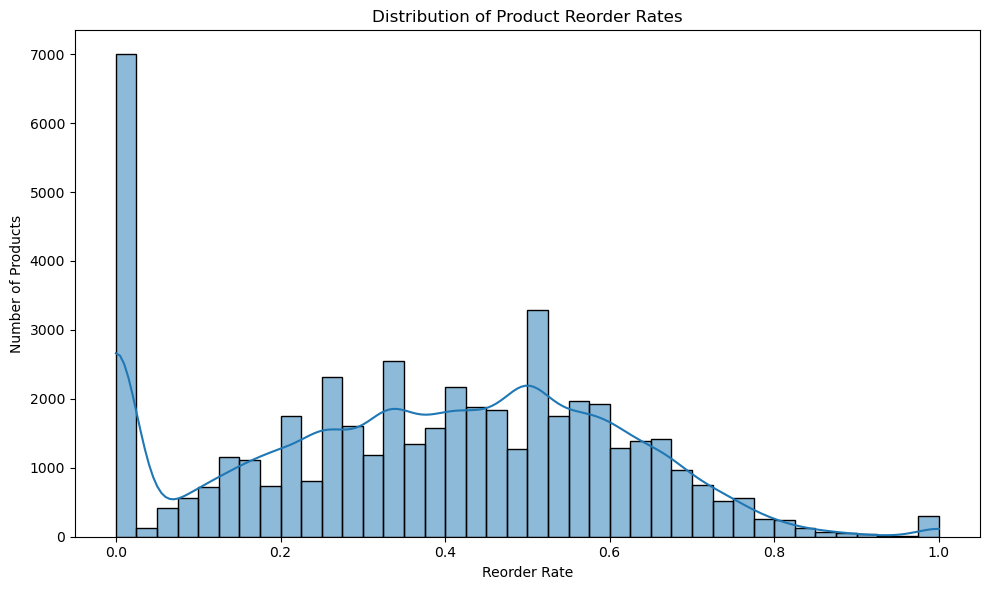

In [17]:
plt.figure(figsize=(10,6))

sns.histplot(
    product_stats["reorder_rate"],
    bins=40,
    kde=True
)

plt.title("Distribution of Product Reorder Rates")
plt.xlabel("Reorder Rate")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()

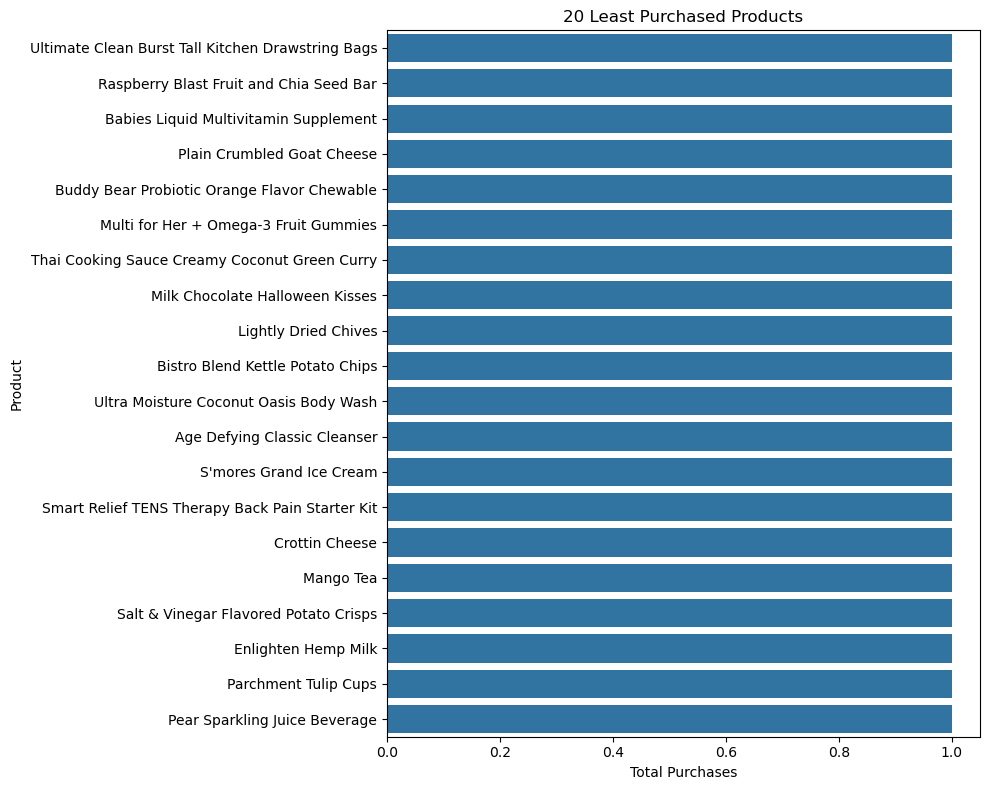

In [18]:
least_purchased = (
    product_stats.sort_values("total_purchases")
                 .head(20)
)

plt.figure(figsize=(10,8))

sns.barplot(
    data=least_purchased,
    y="product_name",
    x="total_purchases"
)

plt.title("20 Least Purchased Products")
plt.xlabel("Total Purchases")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

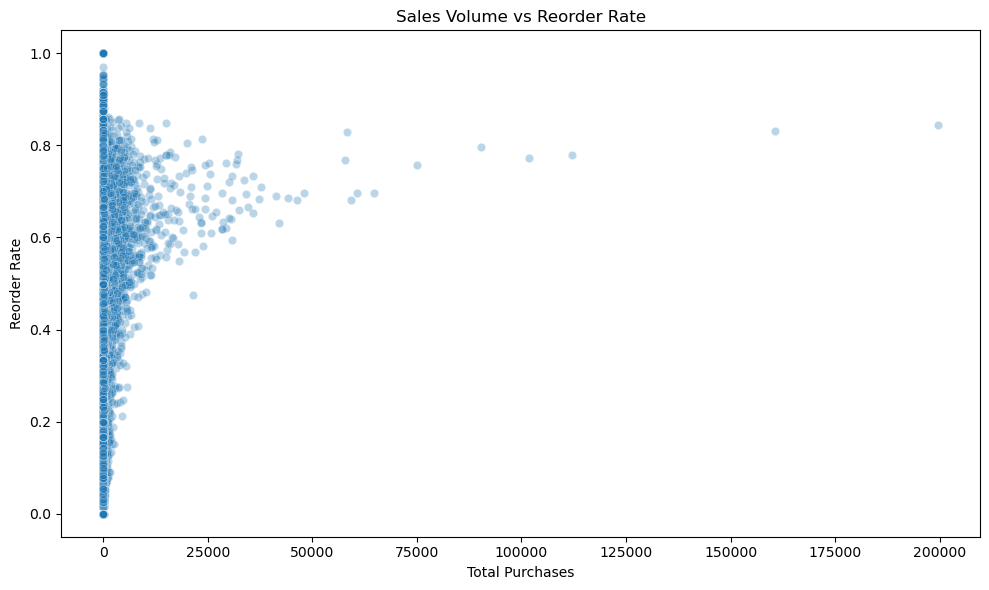

In [19]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=product_stats,
    x="total_purchases",
    y="reorder_rate",
    alpha=0.3
)

plt.title("Sales Volume vs Reorder Rate")
plt.xlabel("Total Purchases")
plt.ylabel("Reorder Rate")
plt.tight_layout()
plt.show()

---
### Which aisles and departments contribute the largest number of orders?
In this section, we aim to identify which product aisles and departments generate the highest number of orders.  
To answer this question, we will use the merged dataset and group the data by aisle and department. Then, we will count the number of products ordered in each category.  
This analysis will help us understand which categories drive the majority of customer purchases and contribute the most to overall sales activity.

In [20]:
df = pd.read_csv("datasets/cleaned_dataset.csv")
top_aisles = df.groupby("aisle")["order_id"].nunique().sort_values(ascending=False).head(15)
top_aisles

In [21]:
top_departments = df.groupby("department")["order_id"].nunique().sort_values(ascending=False).head(15)
top_departments

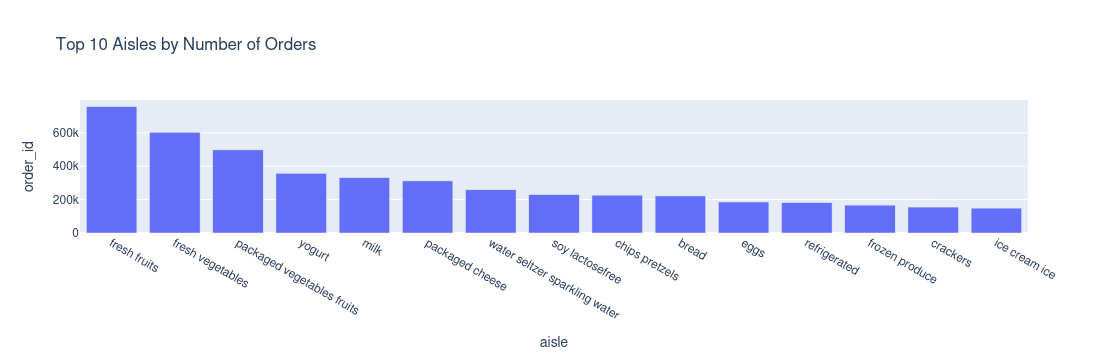

In [22]:
fig = px.bar(
    top_aisles.reset_index(),
    x="aisle",
    y="order_id",
    title="Top 10 Aisles by Number of Orders"
)

fig.show()

The bar chart shows the aisles contributing the largest number of orders.   

Fresh produce categories clearly dominate the ranking, with "fresh fruits" and "fresh vegetables" accounting for the highest number of orders. Dairy products such as yogurt and milk also appear among the most frequently purchased categories. 

This indicates that everyday grocery staples and fresh food products represent the core of customer purchasing behavior.  

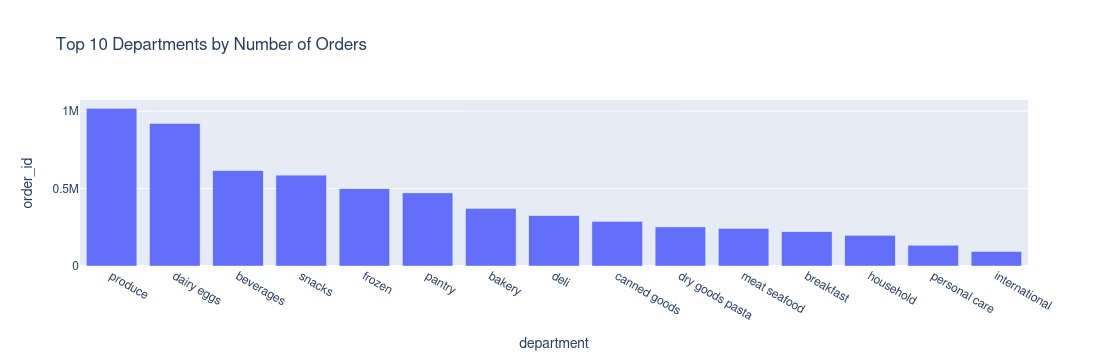

In [23]:
fig = px.bar(
    top_departments.reset_index(),
    x="department",
    y="order_id",
    title="Top 10 Departments by Number of Orders"
)


fig.show()

The bar chart shows which departments contribute the largest number of orders.  

The produce department clearly dominates the ranking, followed by dairy eggs and beverages. These categories represent essential grocery items that customers purchase regularly.  

This indicates that fresh food and everyday staples are the core drivers of customer purchases on the platform.

---

### When do customers usually place orders (day and hour)?


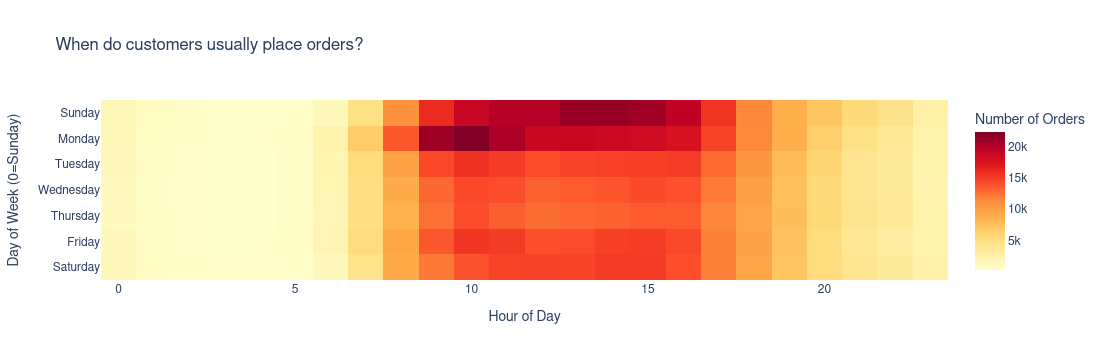

In [24]:
orders_time = (df.groupby(["order_dow","order_hour_of_day"])["order_id"].nunique().reset_index(name="orders"))
pivot_orders = orders_time.pivot(index="order_dow", columns = "order_hour_of_day", values = "orders")

day_labels = ["Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]

pivot_orders.index = day_labels

fig = px.imshow (
    pivot_orders,
    color_continuous_scale = "YlOrRd",
    aspect ="auto",
    labels = dict(x="Hour of Day", y="Day of Week", color="Number of Orders"),
    title = "When do customers usually place orders?"
)

fig.update_layout(xaxis_title="Hour of Day", yaxis_title = "Day of Week (0=Sunday)")

fig.show()


The heatmap shows when customers most frequently place their orders during the week.  

Most orders are placed between approximately 8 AM and 4 PM, with a clear peak around late morning and early afternoon (10 AM – 2 PM).  

Sunday appears to be the most active day for grocery orders, followed by Monday. In contrast, very few orders are placed during nighttime hours.  

This pattern suggests that customers tend to shop during daytime hours, particularly at the beginning of the week, possibly when preparing for the upcoming week.  

---

### Which aisles are frequently purchased together?

In [25]:
# Create aisle presence matrix per order
order_aisle_matrix = pd.crosstab(
    df["order_id"],
    df["aisle"]
)

# Convert counts to binary (presence / absence)
order_aisle_matrix = (order_aisle_matrix > 0).astype(int)

order_aisle_matrix.head()

In [26]:
aisle_corr = order_aisle_matrix.corr()

aisle_corr.head()

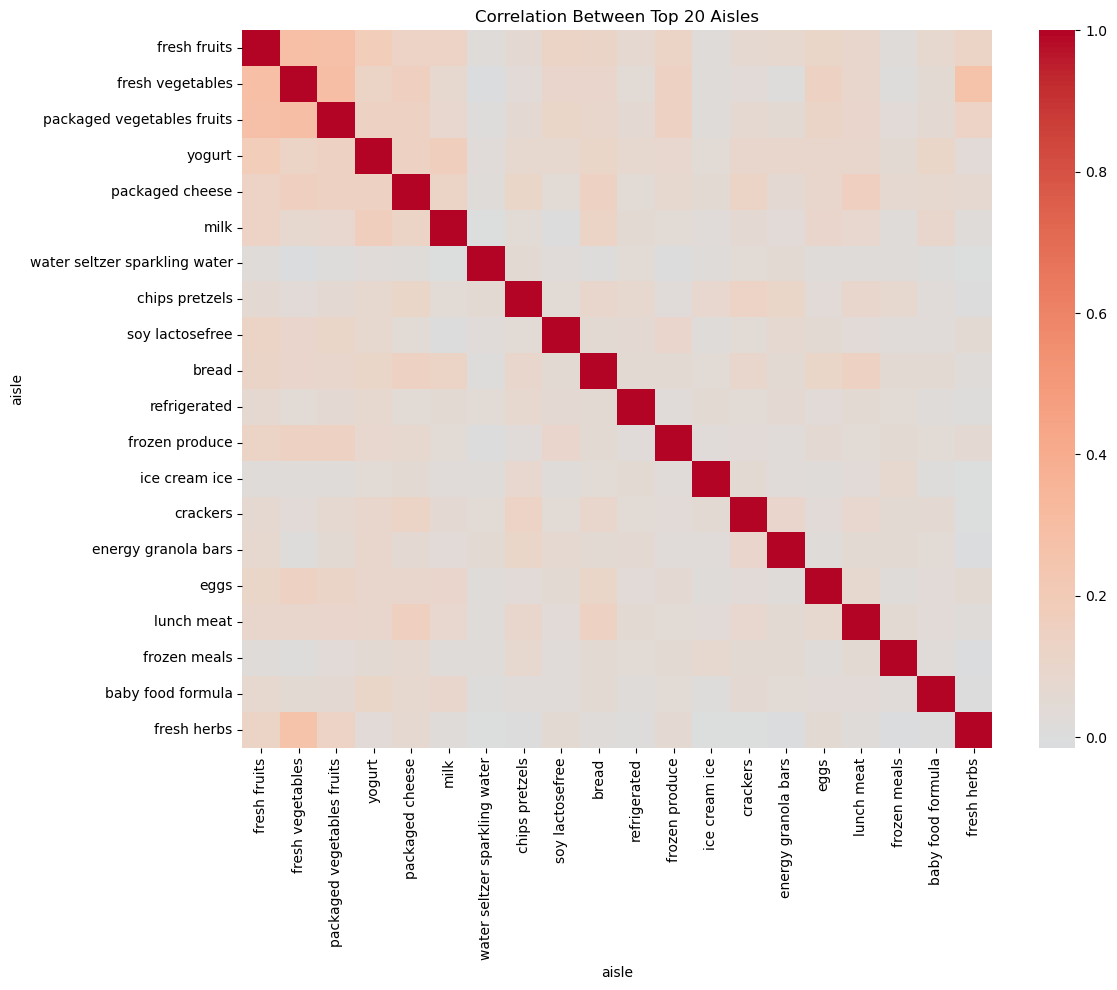

In [27]:
# Select top 20 most frequent aisles
top_aisles = (
    df["aisle"]
      .value_counts()
      .head(20)
      .index
)

corr_subset = aisle_corr.loc[top_aisles, top_aisles]

plt.figure(figsize=(12,10))

sns.heatmap(
    corr_subset,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Top 20 Aisles")
plt.tight_layout()
plt.show()

### After how many days without an order can we consider a customer at risk of churning?

In [28]:
# Relationship between days since prior order and reorder probability

churn_analysis = (
    df.groupby("days_since_prior_order")
      .agg(
          avg_reorder_rate=("reordered", "mean"),
          number_of_orders=("order_id", "count")
      )
      .reset_index()
      .sort_values("days_since_prior_order")
)

churn_analysis.head()

,days_since_prior_order,avg_reorder_rate,number_of_orders
0,0.0,0.739621,191809
1,1.0,0.619382,395825
2,2.0,0.644575,617211
3,3.0,0.668350,795591
4,4.0,0.677265,884494


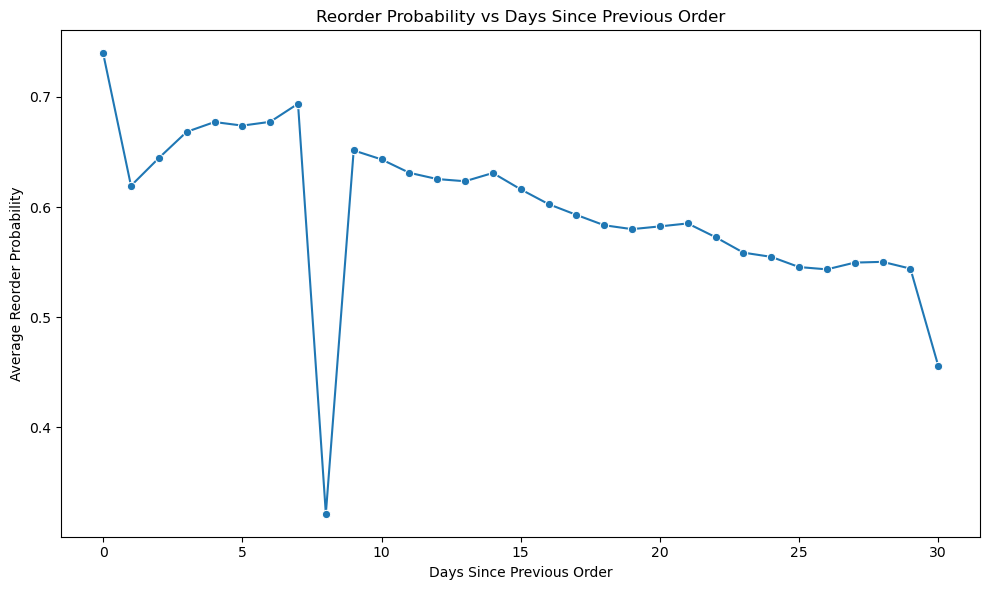

In [29]:
# Visualization
plt.figure(figsize=(10,6))

sns.lineplot(
    data=churn_analysis,
    x="days_since_prior_order",
    y="avg_reorder_rate",
    marker="o"
)

plt.title("Reorder Probability vs Days Since Previous Order")
plt.xlabel("Days Since Previous Order")
plt.ylabel("Average Reorder Probability")
plt.tight_layout()
plt.show()

### Do customers fill their baskets more on weekends or during the week?

In [30]:
# Calculate basket size
basket_size = (
    df.groupby(["order_id", "order_dow"])
      .agg(basket_size=("add_to_cart_order", "max"))
      .reset_index()
)

basket_size.head()

,order_id,order_dow,basket_size
0,2,5.0,9.0
1,4,1.0,13.0
2,6,1.0,3.0
3,8,4.0,1.0
4,20,6.0,8.0


In [31]:
# Label weekends vs weekdays
basket_size["day_type"] = basket_size["order_dow"].apply(
    lambda x: "Weekend" if x in [0,6] else "Weekday"
)

basket_size.head()

,order_id,order_dow,basket_size,day_type
0,2,5.0,9.0,Weekday
1,4,1.0,13.0,Weekday
2,6,1.0,3.0,Weekday
3,8,4.0,1.0,Weekday
4,20,6.0,8.0,Weekend


In [32]:
# Compute average basket size
basket_summary = (
    basket_size.groupby("day_type")
               .agg(
                   avg_basket_size=("basket_size", "mean"),
                   number_of_orders=("order_id", "count")
               )
               .reset_index()
)

basket_summary

,day_type,avg_basket_size,number_of_orders
0,Weekday,9.706008,945495
1,Weekend,10.959407,411972


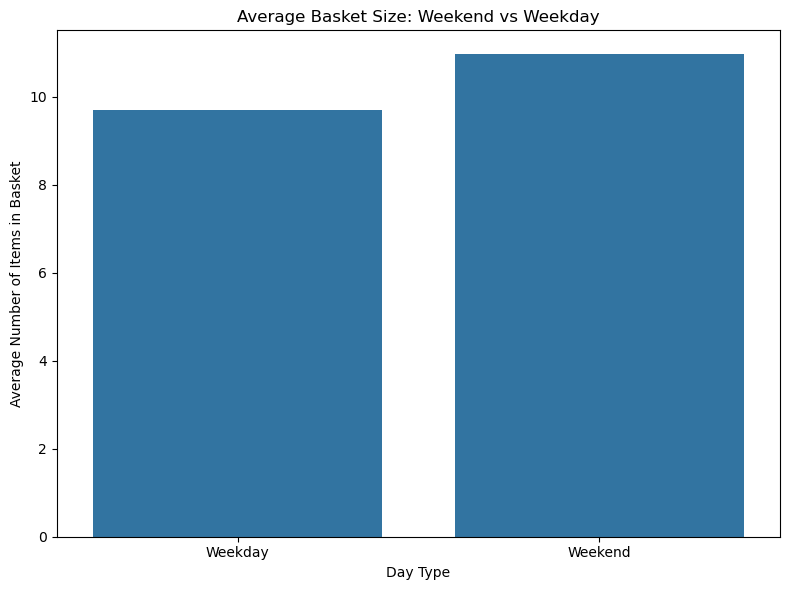

In [33]:
plt.figure(figsize=(8,6))

sns.barplot(
    data=basket_summary,
    x="day_type",
    y="avg_basket_size"
)

plt.title("Average Basket Size: Weekend vs Weekday")
plt.xlabel("Day Type")
plt.ylabel("Average Number of Items in Basket")
Skip to Main
notebook
Last Checkpoint: 6 minutes ago
[Python 3 (ipykernel)]
Kernel Starting

plt.tight_layout()
plt.show()


### At how many items in a basket does a customer tend to stop adding products?


In [34]:
basket_size = df.groupby("order_id")["product_id"].count().reset_index()
basket_size.rename(columns={"product_id":"basket_size"}, inplace=True)
fig = px.histogram(
    basket_size,
    x="basket_size",
    nbins=40,
    title="Distribution of Basket Size",
    labels={"basket_size":"Number of Items in Basket"}
)

fig.show()

The histogram shows that most xuqtomers stop adding products when the basket reaches approximately 5-10 items.

---

### Is there a relationship between the last order and the reorder?

In [35]:
reorder_by_days = df.groupby("days_since_prior_order")["reordered"].mean().reset_index()

fig = px.line(
    reorder_by_days,
    x="days_since_prior_order",
    y="reordered",
    title="Reorder Probability vs Days Since Last Order",
    labels={"days_since_prior_order":"Days Since Prior Order", "reordered":"Reoder Probability"}
)

fig.show()

The plot indicates a general negative relationship between the time since the previous order and the probability of reordering a product.  

Customers who place orders shortly after their previous purchase tend to have a higher reorder probability. As the number of days since the last order increases, the reorder probability gradually decreases.  

---

### After how many days without an order can we consider a customer at risk of churning?

In [36]:
fig = px.histogram(
    df,
    x="days_since_prior_order",
    nbins=30,
    title = "Distribution of Days Between Orders",
    labels = {"days_sicne_proir_order":"Days Between Orders"}
)

fig.show()

To estimate when a customer may be at risk of churning, we analyze the distribution of the number of days between consecutive orders.  

The histogram shows that most customers place their next order within approximately 5 to 10 days after their previous purchase. The number of orders gradually decreases as the gap between orders increases.  

After around 20–25 days without placing a new order, the number of returning customers becomes significantly lower. This suggests that customers who have not ordered for more than about 3–4 weeks could be considered at risk of churning.  

There are also a large number of orders for the 30th and 31st days, based on which we can say that there are “monthly” orders.  

It is also important to note that the spike at 30 days occurs because the dataset caps the variable days_since_prior_order at 30 days.

---

### Is there any relationship between the last order and the reorder?

In [37]:
first_products = df[df["add_to_cart_order"] == 1]

top_first_products = (
    first_products.groupby("product_name").size().reset_index(name="count").sort_values("count", ascending=False).head(20)
)

fig = px.bar(
    top_first_products,
    x = "count",
    y="product_name",
    orientation="h",
    title="Products Most Often Added to the Cart First",
    labels={
        "count":"Number of Times Added First",
        "product_name":"Product"
    },
    height=700
)

fig.update_layout(yaxis={"categoryorder":"total ascending"})

fig.show()

To understand how customers begin building their shopping baskets, we analyze the products that are most frequently added first to the cart.

The results show that staple grocery items such as bananas, milk, avocados, and berries are most often the first products added. Fresh produce clearly dominates the list.

This suggests that customers tend to start their shopping with commonly purchased essentials before adding other items.

From a business perspective, these products could be strategically highlighted on the homepage or placed prominently in stores to guide the rest of the shopping experience.

---

### Can we predict the reorder of a product by a specific buyer?

In [ ]:
def init_neural_ia(iteration = 500):
    """
    crée un model d'ia neural network et le renvoie
    """
    model = MLPClassifier(

        hidden_layer_sizes=(100),     # crée les "hiddden layers"
        activation='relu',                # fait en sorte que si les lien des neuronnes sont inferieur a 0 les mettent a 0
        solver='adam',                    # fait en sorte que plus le resultat est proche de la valeur attendue moins il fluctue les modificatio
        max_iter=iteration                # le nombre d'iteration
    )
    return model


def reorder_df(df):
    
    user_col = df.groupby('user_id').agg(
        user_total_orders = ('order_number', 'max'),
        user_moy_basket_size = ('product_id', 'count'),
        user_moy_reorder_days = ('days_since_prior_order', 'mean'),
    ).reset_index()

    # collones produit
    prod_col = df.groupby('product_id').agg(
        product_total_orders = ('order_id', 'count'),
        product_reorder_rate = ('reordered', 'mean'),
    ).reset_index()

    # Collones des 2
    fus_col = df.groupby(['user_id', 'product_id']).agg(
        fus_order_count = ('order_id', 'count'),
        fus_avg_cart_position = ('add_to_cart_order', 'mean'),
        fus_last_order = ('order_number', 'max'),
    ).reset_index()

    # Création de la nouvelle df
    df_new = (df[['user_id', 'product_id', 'reordered']]
                .merge(user_col, on='user_id', how='left')
                .merge(prod_col, on='product_id', how='left')
                .merge(fus_col, on=['user_id', 'product_id'], how='left')
                .drop_duplicates(subset=['user_id', 'product_id'])
                .reset_index(drop=True))
    return df_new

In [39]:
df_reord = reorder_df(df)
df_reord

In [40]:
inputt = df_reord.drop('reordered' , axis=1)
output = df_reord['reordered']

input_train, input_test, output_train, output_test = train_test_split(inputt, output, test_size=0.2, random_state=24, stratify=output)

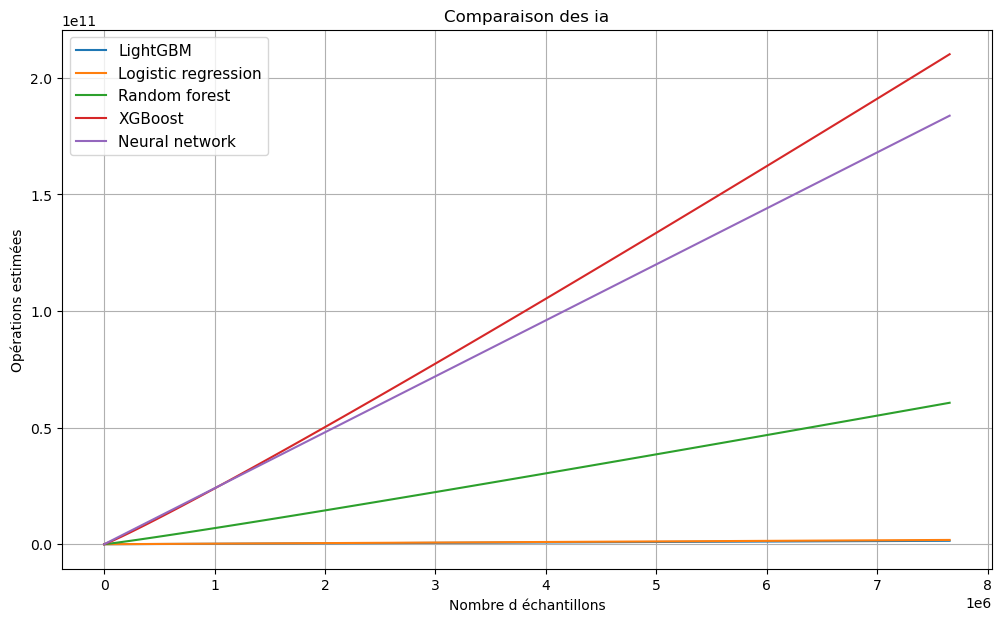

In [31]:

N = np.linspace(1, 7656670, 100)

# Constantes fixées (
d = 12            # Nombre de features (colonnes)
K = 100           # Nombre d'arbres (pour RFXGB et LGBM)
I = 20            # Nombre d'itérations (LogReg, NN)
nn = d * 100    # Poids du Neural Network


# Logistic regression= O(I*N*d)
logreg = I * N * d

# Random forest = O(K*N*log(N)*sqrt(d) )
rf = K * N * np.log2(N) * np.sqrt(d)

# xgboost = O(K*N*log(N)*d)
xgb = K * N * np.log2(N) * d

# Lightgbm= O(K * N_sample * d_bundle)
lgbm = K * (N * 0.2) * (d * 0.8)

#xgboost = O(K*N*log(N)*d)
xgb = K * N * np.log2(N) * d

#Neural network = O(I*N*W)
nn = I * N * nn


plt.figure(figsize=(12, 7))

# Tracer des courbes
plt.plot(N, lgbm, label='LightGBM')
plt.plot(N, logreg, label='Logistic regression')
plt.plot(N, rf, label='Random forest')

plt.plot(N, xgb, label='XGBoost')
plt.plot(N, nn, label='Neural network')

# Label
plt.title('Comparaison des ia')
plt.xlabel('Nombre d échantillons')
plt.ylabel('Opérations estimées')
plt.legend(fontsize=11)
plt.grid(True)

# Affichage
plt.show()

### Le meilleur modéle pour notre cas est le lightGBM

In [17]:
def reorder_df(df):
    
    user_col = df.groupby('user_id').agg(
        user_total_orders = ('order_number', 'max'),
        user_moy_basket_size = ('product_id', 'count'),
        user_moy_reorder_days = ('days_since_prior_order', 'mean'),
    ).reset_index()
    
    
    # collones produit
    prod_col = df.groupby('product_id').agg(
        product_total_orders = ('order_id', 'count'),
        product_reorder_rate = ('reordered', 'mean'),
    ).reset_index()
    
    # Collones des 2
    fus_col = df.groupby(['user_id', 'product_id']).agg(
        fus_order_count = ('order_id', 'count'),
        fus_avg_cart_position = ('add_to_cart_order', 'mean'),
        fus_last_order = ('order_number', 'max'),
    ).reset_index()

    
    # Création de la nouvelle df
    df_new = (df[['user_id', 'product_id', 'reordered']].merge(user_col, on='user_id', how='left')
                .merge(prod_col, on='product_id', how='left')
                .merge(fus_col, on=['user_id', 'product_id'], how='left')
                .drop_duplicates(subset=['user_id', 'product_id'])
                .reset_index(drop=True))
    return df_new

In [ ]:
df_reord

In [ ]:
def init_lightgbm(n_estimators=100):
    model = lgb.LGBMClassifier(
        n_estimators = n_estimators,
        verbose=-1
    )
    return model

In [65]:
light_reorder = init_lightgbm()
light_reorder.fit(input_train, output_train)

KeyboardInterrupt: 

In [ ]:
output_pred = light_reorder.predict(input_test)

accuracy = accuracy_score(output_test, output_pred)

print(f"Accuracy : {accuracy_score(output_test, output_pred):.2%}")

In [45]:
importance = pd.DataFrame({
    "feature": input_train.columns,
    "importance": light_reorder.feature_importances_
})

importance = importance.sort_values("importance", ascending=False)

fig = px.bar(
    importance,
    x="importance",
    y="feature",
    orientation="h",
    title="Model Feature Importance"
)

fig.show()

In [46]:
model_package = {
    "model": light_reorder,
    "features": list(input_train.columns),
    "model_type": "LightGBM",
    "accuracy" : accuracy
}

joblib.dump(model_package, "reorder_model.pkl")

print("Model package saved")

### Can we predict the number of items in a customer's next basket?

In [88]:
def basket_df(df):
   
    order_col = (df.groupby(["user_id", "order_id", "order_number","order_hour_of_day", "days_since_prior_order"]).agg(
        basket_size = ('product_id', 'count'),
        num_reordered = ("reordered", "sum"),
        reorder_rate = ("reordered", "mean"),
        num_departments = ("department_id", "nunique"),
        num_aisles = ("aisle_id", "nunique"),
    ).reset_index().sort_values(["user_id", "order_number"]))

    g = order_col.groupby("user_id")
    
    order_col["target_next_basket_size"] = g["basket_size"].shift(-1)
    order_col["avg_basket_size"] = g["basket_size"].transform("mean")
    
    final_df = order_col.dropna(subset=["target_next_basket_size"]).drop(columns= ["order_id","user_id"]).copy()
    
    return final_df

In [89]:
df_basket = basket_df(df)

In [90]:
inputt_basket = df_basket.drop('target_next_basket_size' , axis=1)
output_basket = df_basket['target_next_basket_size']

input_train, input_test, output_train, output_test = train_test_split(inputt_basket, output_basket, test_size=0.2, random_state=42)

In [91]:
light_basket = lgb.LGBMRegressor(
    n_estimators=1000,      # plus d'arbres
    learning_rate=0.01,    # plus lent mais plus précis
    num_leaves=30,         # arbres plus profonds
    min_child_samples=20,
)
light_basket.fit(input_train, output_train)

,boosting_type,'gbdt'
,num_leaves,30
,max_depth,-1
,learning_rate,0.01
,n_estimators,1000
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [92]:
output_pred = light_basket.predict(input_test)
accuracy = r2_score(output_test, output_pred)
print(f"R²   : {accuracy:.4f}")
print(f"MAE  : {mean_absolute_error(output_test, output_pred):.4f}")

R²   : 0.5783
MAE  : 3.4409


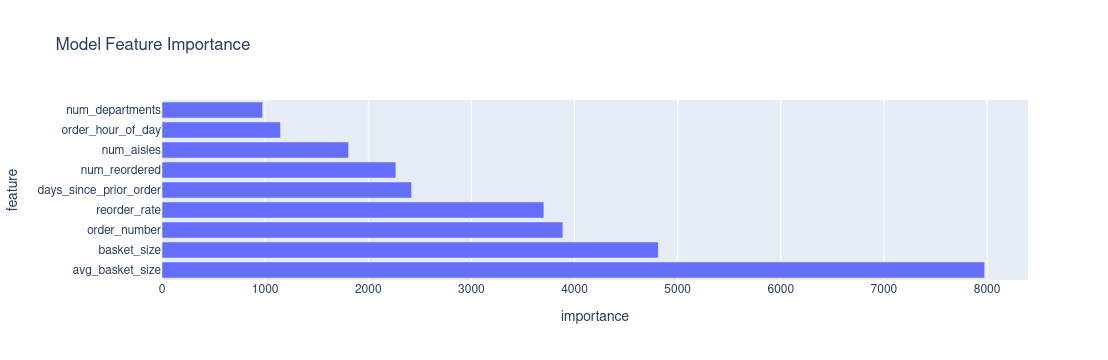

In [93]:
importance = pd.DataFrame({
    "feature": input_train.columns,
    "importance": light_basket.feature_importances_
})

importance = importance.sort_values("importance", ascending=False)

fig = px.bar(
    importance,
    x="importance",
    y="feature",
    orientation="h",
    title="Model Feature Importance"
)

fig.show()

In [94]:
model_package = {
    "model": light_basket,
    "features": list(input_train.columns),
    "model_type": "LightGBM",
    "accuracy" : accuracy
}

joblib.dump(model_package, "basket_model.pkl")

['basket_model.pkl']

### Can we predict a buyer's shopping cart based on their past purchases?

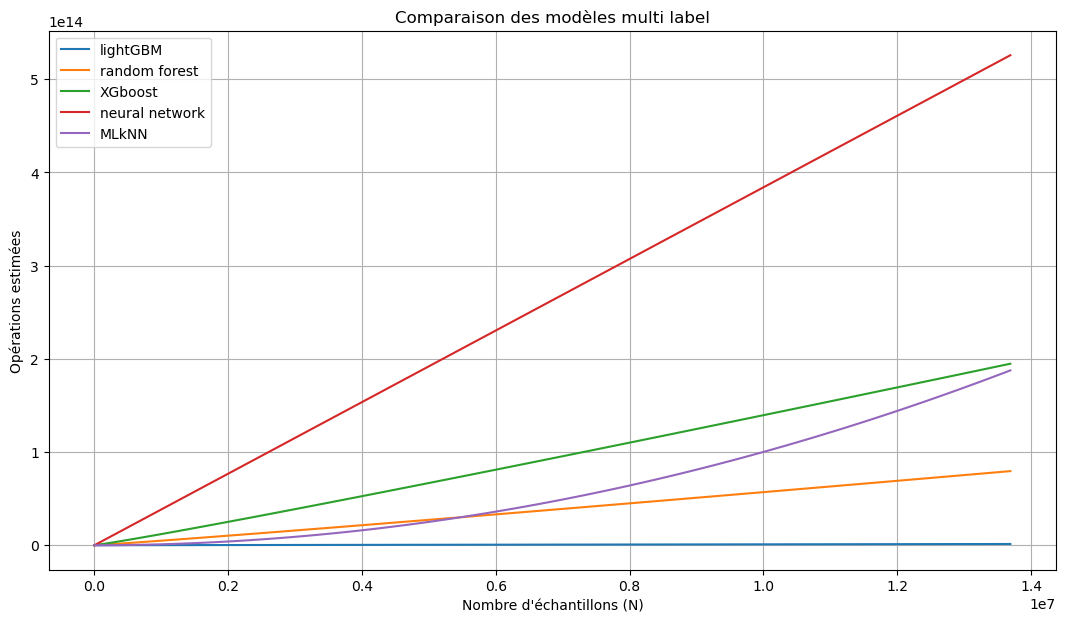

In [17]:
N = np.linspace(1, 13690738, 100)

# Constantes

D = 6                                           # nombre de collones
K = 100                                         # nombre d arbres
I = 100                                         # nombre d itérations pour logistic regression et neural network)
W = D * 64                                      # nobmre de neuronnes dans le neural network
L = 1000                                        # nombre de produits
k = 10                                          # nombre de voisin  du mlknn

# formule de complexité des modeles en multi label

lr = I * N * D * L                               # O(I*N*d*L)
rf = K * N * np.log2(N) * np.sqrt(D) * L         # O(K*N*log(N)*d^-1*L)
xgb = K * N * np.log2(N) * D * L                 # O(K*N*log(N)*d*L)
lgbm = K * (N * 0.2) * (D * 0.8) * L             # O(K*0.2N*0.8*L)
nn = I * N * W * L                               # O(I*N*W*L)
mlknn = N**2 + N * k * L                         # O(N²*N*k*L)

plt.figure(figsize=(13, 7))

# tracée des courbes

plt.plot(N, lgbm, label="lightGBM")
plt.plot(N, rf, label="random forest")
plt.plot(N, xgb, label="XGboost")
plt.plot(N, nn, label="neural network")
plt.plot(N, mlknn, label="MLkNN")

plt.title(f"Comparaison des modèles multi label")
plt.xlabel("Nombre d'échantillons (N)")
plt.ylabel("Opérations estimées")
plt.legend(fontsize=10)
plt.grid(True)

In [71]:
def cart_df(df):
    
    df = df.sort_values(["user_id", "order_number"])
    
    last_order_per_user = df.groupby("user_id")["order_number"].transform("max")
    
    mask_last  = df["order_number"] == last_order_per_user
    mask_prior = df["order_number"] != last_order_per_user

    df_prior  = df[mask_prior].copy()
    df_target = df[mask_last].copy()

    target_products = (df_target.groupby("user_id")["product_id"].apply(set).rename("target_products"))

    order_stats = (df_prior.drop_duplicates(["user_id", "order_id"])[["user_id", "order_id", "order_number", "order_dow","order_hour_of_day", "days_since_prior_order"]])

    basket_sizes = (df_prior.groupby(["user_id", "order_id"]).size().reset_index(name="basket_size"))

    user_basket = basket_sizes.groupby("user_id")["basket_size"].agg(user_avg_basket_size="mean",u_std_basket_size="std",).fillna(0)

    user_temporal = order_stats.groupby("user_id").agg(
        user_nb_orders=("order_id","nunique"),
        user_avg_days_between=("days_since_prior_order", "mean"),
        user_std_days_between=("days_since_prior_order","std"),
        user_avg_order_dow=("order_dow","mean"),
        user_avg_order_hour=("order_hour_of_day", "mean"),
    ).fillna(0)

    user_reorder = df_prior.groupby("user_id").agg(
        user_reorder_rate=("reordered","mean"),
        user_nb_unique_products=("product_id","nunique"),
        user_nb_unique_aisles=("aisle_id","nunique"),
        user_nb_unique_depts=("department_id" ,"nunique"),
    )
    product_features = df_prior.groupby("product_id").agg(
        prod_nb_orders=("order_id","count"),
        prod_nb_users=("user_id","nunique"),
        prod_reorder_rate=("reordered","mean"),
        prod_avg_add_to_cart_pos=("add_to_cart_order", "mean"),
    )
    user_features = user_temporal.join(user_basket).join(user_reorder)



    max_order_per_user = (df_prior.groupby("user_id")["order_number"].max().rename("user_max_order_number"))

    user_prod = df_prior.groupby(["user_id", "product_id"]).agg(
        user_prod_nb_orders=("order_id","count"),
        user_prod_first_order_number=("order_number","min"),
        user_prod_last_order_number=("order_number","max"),
        user_prod_reorder=("reordered","mean"),
        user_prod_avg_to_cart=("add_to_cart_order","mean"),
    ).reset_index()

    
    user_prod = user_prod.join(max_order_per_user, on="user_id")
    user_prod["user_prod_orders_since_last"] = user_prod["user_max_order_number"] - user_prod["user_prod_last_order_number"]
    user_prod["user_prod_pct_orders_present"] = user_prod["user_prod_nb_orders"] / user_prod["user_max_order_number"]
    user_prod = user_prod.drop(columns=["user_max_order_number"])

    result = (user_prod.join(user_features,on="user_id").join(product_features,on="product_id"))
    result = result.join(target_products, on="user_id")
    
    
    result["reordered"] = result.apply(
        lambda row: int(row["product_id"] in row["target_products"])
        if isinstance(row["target_products"], set) else 0,
        axis=1
    )
    result = result.drop(columns=["target_products"])

    return result

In [72]:
def use_ia(model, df):
    """
    model : LightGBM déjà entraîné (avec model.fit())
    df    : historique d'un utilisateur (toutes ses commandes passées)
    """
    features_df = cart_df(df)

    # garder les ids pour les réattacher après
    ids = features_df[["user_id", "product_id"]].copy()

    # prédiction directe 
    inputt = features_df.drop(columns=["user_id", "product_id", "reordered"])    
    probas = model.predict_proba(inputt)[:, 1]

    # reconstruire le résultat
    ids["proba_reorder"] = probas
    product_names = df[["product_id", "product_name"]].drop_duplicates("product_id")
    ids = ids.merge(product_names, on="product_id", how="left")

    return ids.sort_values(["user_id", "proba_reorder"], ascending=[True, False]).reset_index(drop=True)    

In [97]:
# separer la df en 2 pour l'entrainement et les test
train, test = train_test_split(df, test_size=0.2, random_state=42)

# remodeler la df pour que elle soit utilisable
df_cart_train = cart_df(train)

# separer l'input et l'output en et les id pour par que l'ia les prennent en compte
ids_train = df_cart_train[["user_id", "product_id"]]
input_train = df_cart_train.drop(columns=["user_id", "product_id", "reordered"])
output_train = df_cart_train["reordered"]

In [ ]:
#entrainement de l'ia 
model = lgb.LGBMClassifier()
model.fit(input_train, output_train)

In [84]:
df_test = cart_df(test)

X_test = df_test.drop(columns=["user_id", "product_id", "reordered"])
y_true = df_test["reordered"]
y_proba = model.predict_proba(X_test)[:, 1]

In [85]:
auc = roc_auc_score(y_true, y_proba) * 100
print(f"AUC : {auc:.4f}")

AUC : 71.0623


In [ ]:
# utilisation de l'ia
use_ia(model, test)

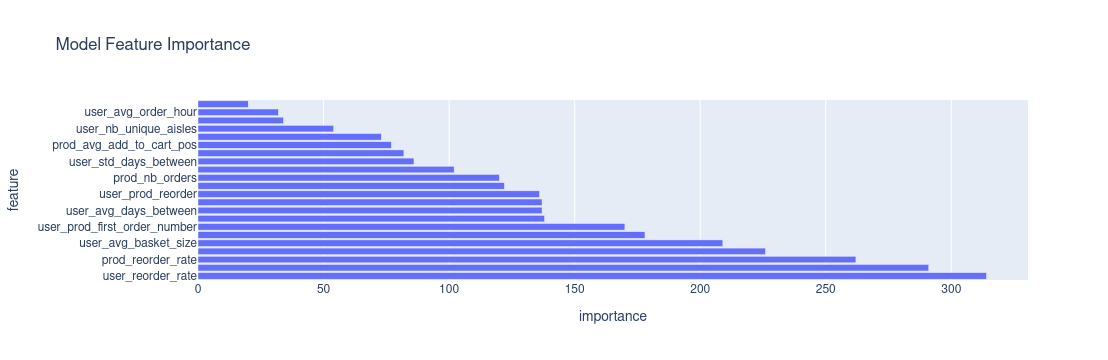

In [98]:
importance = pd.DataFrame({
    "feature": input_train.columns,
    "importance": model.feature_importances_
})

importance = importance.sort_values("importance", ascending=False)

fig = px.bar(
    importance,
    x="importance",
    y="feature",
    orientation="h",
    title="Model Feature Importance"
)

fig.show()

In [87]:
model_package = {
    "model": model,
    "features": list(input_train.columns),
    "model_type": "LightGBM",
    "accuracy" : auc
}

joblib.dump(model_package, "cart_model.pkl")

['cart_model.pkl']

### Which products are most often added to the shopping cart together?

In [ ]:
from mlxtend.frequent_patterns import apriori, association_rules

# Create basket format: rows = orders, columns = products
basket = df.groupby(['order_id', 'product_name'])['product_id'] \
           .count().unstack().fillna(0)

# Convert counts to 1/0 (product present or not)
basket = basket.applymap(lambda x: 1 if x > 0 else 0)

print("Basket shape:", basket.shape)
basket.head()

In [ ]:
# Keep products appearing in at least 500 orders
# Reduces dataset size (optional but doesn't use as much power)
product_freq = basket.sum().sort_values(ascending=False)
popular_products = product_freq[product_freq >= 500].index

basket_filtered = basket[popular_products]

print("Filtered basket shape:", basket_filtered.shape)

In [ ]:
# Generates the rules to make the pairs
frequent_items = apriori(
    basket_filtered,
    min_support=0.01,   # appears in at least 1% of orders
    use_colnames=True
)

frequent_items = frequent_items.sort_values("support", ascending=False)

frequent_items.head(10)

In [ ]:
rules = association_rules(
    frequent_items,
    metric="lift",
    min_threshold=1
)

rules = rules.sort_values("lift", ascending=False)

rules.head(10)

In [ ]:
# Extracts the product pairs
rules["antecedents_len"] = rules["antecedents"].apply(lambda x: len(x))
rules["consequents_len"] = rules["consequents"].apply(lambda x: len(x))

product_pairs = rules[
    (rules["antecedents_len"] == 1) &
    (rules["consequents_len"] == 1)
]

product_pairs = product_pairs.sort_values("lift", ascending=False)

product_pairs[['antecedents','consequents','support','confidence','lift']].head(15)

In [ ]:
# Visualization
top_pairs = product_pairs.head(10).copy()

top_pairs["pair"] = top_pairs.apply(
    lambda row: list(row["antecedents"])[0] + " + " + list(row["consequents"])[0],
    axis=1
)

plt.figure(figsize=(10,6))
sns.barplot(data=top_pairs, y="pair", x="lift", palette="viridis")

plt.title("Top Product Pairs Frequently Bought Together")
plt.xlabel("Lift Score")
plt.ylabel("Product Pair")
plt.show()